# Module 5: Machine Learning Fundamentals: hands-on lab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prajwalskandas31-sudo/ai-engineering-course/blob/main/module-05-ml-fundamentals/Module_5_Lab.ipynb)

Part of the free **AI Engineering Course** by Tech with Prajwal. ▶️ [Module 5 videos](https://www.youtube.com/playlist?list=PLL8oIdsEel2Y) · 📒 [Study notes (Notion)](https://chipped-willow-4a2.notion.site/4066f1ed006e811d9770eb5c592b078f) · 💻 [Module 5 on GitHub](https://github.com/prajwalskandas31-sudo/ai-engineering-course/tree/main/module-05-ml-fundamentals)

**How to use:** run the cells from top to bottom (**Runtime → Run all**), or one at a time with **Shift + Enter**. Everything this lab needs is already installed in Google Colab. Change the numbers and re-run to experiment.

## ml_practical_lesson.py

Module 5: Machine Learning Fundamentals - Practical Hands-On Exercise
---------------------------------------------------------------------
Scenario: Predicting Mouse Speed based on Mouse Weight (inspired by StatQuest examples)

This hands-on script demonstrates:
1. Data Generation & Train/Test Splitting (Preventing Data Leakage)
2. High Bias (Underfitting) with Linear Model (Degree 1 - Straight Line)
3. High Variance (Overfitting) with High-Degree Polynomial (Degree 10 - Squiggly Line)
4. Finding the "Sweet Spot" using K-Fold Cross-Validation (Model Selection)
5. Final Unbiased Test Set Evaluation

Tech with Prajwal - AI Engineering Course

In [1]:
import numpy as np
import matplotlib
matplotlib.use("Agg")  # save the plot to a file; works without a display
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

### Set random seed for reproducible results

In [2]:
# Set random seed for reproducible results
np.random.seed(42)

### `generate_mouse_data()`: Simulates real-world noisy data following a true curved pattern:

In [3]:
def generate_mouse_data(n_samples=50):
    """
    Simulates real-world noisy data following a true curved pattern:
    True Relationship: Speed = 2.0 + 3.5 * Weight - 0.8 * Weight^2 + Gaussian Noise
    """
    weights = np.sort(np.random.uniform(0.5, 5.0, n_samples))
    true_speed = 2.0 + 3.5 * weights - 0.8 * (weights ** 2)
    noise = np.random.normal(0, 0.8, n_samples)
    observed_speed = true_speed + noise
    return weights.reshape(-1, 1), observed_speed

### `build_model()`

In [4]:
def build_model(degree):
    # StandardScaler first: without it, weight^10 reaches ~10 million and the
    # high-degree fit becomes numerically unstable.
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree=degree), LinearRegression())

### `main()`

In [5]:
def main():
    print("=" * 60)
    print("MODULE 5: PRACTICAL MACHINE LEARNING LESSON")
    print("=" * 60)

    # 1. GENERATE & SPLIT DATA
    X, y = generate_mouse_data(n_samples=50)

    # Split into 80% Training set and 20% Testing set
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    print(f"\n[Step 1] Dataset Created & Split:")
    print(f" - Total Samples: {len(X)}")
    print(f" - Training Set Size: {len(X_train)} samples (80%)")
    print(f" - Testing Set Size: {len(X_test)} samples (20%) [Kept secret until final evaluation]")

    # 2. COMPARE MODELS: HIGH BIAS VS HIGH VARIANCE VS SWEET SPOT
    degrees = [1, 2, 10]
    model_names = {
        1: "Degree 1: Linear Model (expected: High Bias / Underfitting - Straight Line)",
        2: "Degree 2: Quadratic Model (expected: Sweet Spot)",
        10: "Degree 10: High Polynomial Model (expected: High Variance / Overfitting - Squiggly Line)",
    }

    print("\n[Step 2] Training Candidate Models & Cross-Validating (Training Data Only):")
    print("-" * 60)

    results = {}
    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    for deg in degrees:
        model = build_model(deg)

        # K-Fold Cross-Validation on Training Data (5 folds of 8 samples)
        cv_scores = cross_val_score(model, X_train, y_train, cv=kf,
                                    scoring="neg_root_mean_squared_error")
        cv_rmse = -np.mean(cv_scores)

        # Fit on the full Training Data
        model.fit(X_train, y_train)
        train_rmse = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))

        results[deg] = {"model": model, "train_rmse": train_rmse, "cv_rmse": cv_rmse}

        print(f"\nModel: {model_names[deg]}")
        print(f"  -> Training RMSE:   {train_rmse:.4f}")
        print(f"  -> 5-Fold CV RMSE:  {cv_rmse:.4f} (Used for Model Selection)")

    # 3. MODEL SELECTION: pick the lowest cross-validation error
    best_deg = min(results, key=lambda d: results[d]["cv_rmse"])
    print("\n[Step 3] Model Selection:")
    print(f" -> Lowest CV RMSE: Degree {best_deg} ({results[best_deg]['cv_rmse']:.4f})")

    # 4. FINAL EVALUATION ON THE TEST SET (opened only now)
    print("\n[Step 4] Test Set Evaluation (for comparison; the choice is already made):")
    for deg in degrees:
        test_rmse = np.sqrt(mean_squared_error(y_test, results[deg]["model"].predict(X_test)))
        results[deg]["test_rmse"] = test_rmse
        marker = "  <- selected" if deg == best_deg else ""
        print(f"  Degree {deg:>2}: Test RMSE {test_rmse:.4f}{marker}")

    # 5. INTERPRETATION, computed from the numbers above
    r1, r2, r10 = results[1], results[2], results[10]
    print("\n" + "=" * 60)
    print("KEY PRACTICAL TAKEAWAYS (from this run's numbers):")
    print("=" * 60)
    print(f"1. High Bias (Degree 1): highest error on training ({r1['train_rmse']:.2f}), "
          f"CV ({r1['cv_rmse']:.2f}) and test ({r1['test_rmse']:.2f}) data. It underfits.")
    print(f"2. High Variance (Degree 10): lowest training error ({r10['train_rmse']:.2f}), "
          f"but its CV error ({r10['cv_rmse']:.2f}) is worse than Degree 2's ({r2['cv_rmse']:.2f}).")
    print("   The gap between training and CV error is the overfitting signal.")
    print(f"3. K-Fold Cross-Validation selected Degree {best_deg} without ever touching the test set.")
    print("4. With only 10 test samples, a single test score is noisy. Degree 10 can land close to")
    print("   Degree 2 on this split by luck. That is exactly why we select with CV, not with one split.")
    print("=" * 60)

    # 6. VISUALISE THE THREE FITS
    grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
    for ax, deg in zip(axes, degrees):
        ax.scatter(X_train, y_train, label="Training data", alpha=0.8)
        ax.scatter(X_test, y_test, label="Testing data", marker="s", alpha=0.8)
        ax.plot(grid, results[deg]["model"].predict(grid), color="black", linewidth=2)
        ax.set_title(f"Degree {deg}  |  CV RMSE {results[deg]['cv_rmse']:.2f}")
        ax.set_xlabel("Mouse weight (g)")
        ax.set_ylim(y.min() - 2, y.max() + 2)
    axes[0].set_ylabel("Top speed (cm/s)")
    axes[0].legend()
    fig.suptitle("Underfit vs sweet spot vs overfit")
    fig.tight_layout()
    fig.savefig("bias_variance_fits.png", dpi=120)
    print("\nPlot saved to bias_variance_fits.png")

### Run the lab

In [6]:
main()

MODULE 5: PRACTICAL MACHINE LEARNING LESSON

[Step 1] Dataset Created & Split:
 - Total Samples: 50
 - Training Set Size: 40 samples (80%)
 - Testing Set Size: 10 samples (20%) [Kept secret until final evaluation]

[Step 2] Training Candidate Models & Cross-Validating (Training Data Only):
------------------------------------------------------------

Model: Degree 1: Linear Model (expected: High Bias / Underfitting - Straight Line)
  -> Training RMSE:   1.3505
  -> 5-Fold CV RMSE:  1.3565 (Used for Model Selection)

Model: Degree 2: Quadratic Model (expected: Sweet Spot)
  -> Training RMSE:   0.7186
  -> 5-Fold CV RMSE:  0.7812 (Used for Model Selection)

Model: Degree 10: High Polynomial Model (expected: High Variance / Overfitting - Squiggly Line)
  -> Training RMSE:   0.6423
  -> 5-Fold CV RMSE:  1.0006 (Used for Model Selection)

[Step 3] Model Selection:
 -> Lowest CV RMSE: Degree 2 (0.7812)

[Step 4] Test Set Evaluation (for comparison; the choice is already made):
  Degree  1: T

### Show `bias_variance_fits.png`

The script saves its chart to a file. This cell displays it.

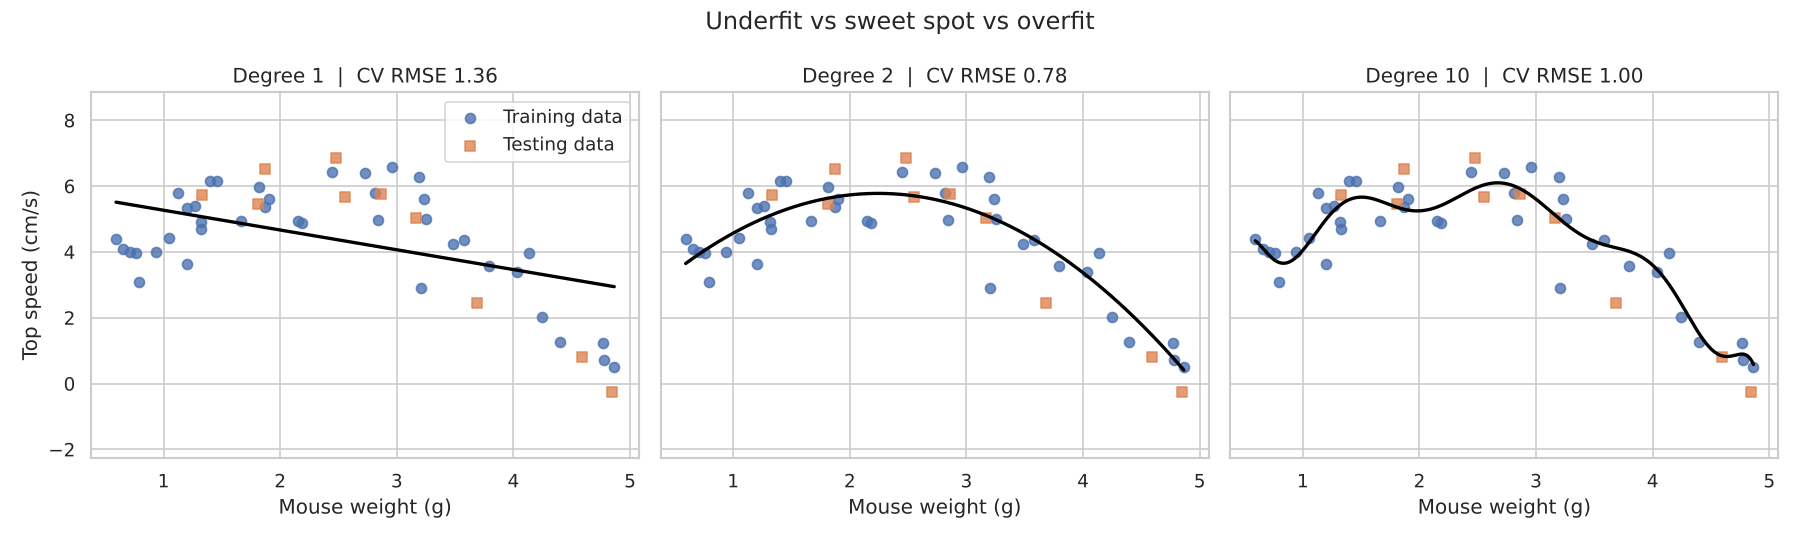

In [7]:
from IPython.display import Image, display
display(Image("bias_variance_fits.png"))

---

💼 [LinkedIn](https://www.linkedin.com/in/prajwalskandas) · 💻 [GitHub](https://github.com/prajwalskandas31-sudo) · 🏠 [Course home](https://chipped-willow-4a2.notion.site/AI-Engineering-Course-Tech-with-Prajwal-4056f1ed006e819e88c5c3d15d1b2e0c)